# kNN Graph + Louvain (ENGLISH) with grid search + file outputs + graphs

In [5]:
import re, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from sentence_transformers import SentenceTransformer
from sklearn.neighbors import NearestNeighbors
import networkx as nx
from community.community_louvain import best_partition              # python-louvain
from matplotlib.backends.backend_pdf import PdfPages


## 0) LOAD DATA 

In [17]:
# Options of data "CSLB_raw", "Sit_Conc_raw"
DATA_NAME = "Sit_Conc_raw"
CSV_PATH = f"../data/{DATA_NAME}.csv"     # <-- change to your CSV name if needed
OUTPUT_PREFIX = "../data/results/en/en"  # files will be prefixed with this

# Robust read: try comma, else semicolon
try:
    df = pd.read_csv(CSV_PATH, encoding='ISO-8859-1', encoding_errors='ignore')
    if not {"concept","participant","property"}.issubset(df.columns):
        raise ValueError("Columns not found with comma delimiter")
except Exception:
    df = pd.read_csv(CSV_PATH, sep=";", engine="python", encoding='ISO-8859-1', encoding_errors='ignore')

required_cols = {"concept","participant","property"}
assert required_cols.issubset(df.columns), f"CSV must have columns {required_cols}"


## 1) LIGHT NORMALIZATION (ENGLISH)


Keep it light to preserve meaning: lowercase, strip punctuation, remove common stopwords.

In [18]:
start = time.time()

EN_STOP = set("""
the a an and or but so to of for from in on at as by is are was were be been being
this that those these there here it its itself they them their you your we our us he she her his
with without into onto about over under out up down not no yes very more most less least
can could should would may might will shall do does did doing done have has had having
than then if else when while where who whom whose which what why how
""".split())

def normalize_text_en(s: str):
    s = str(s).lower().strip()
    # remove punctuation and symbols; keep letters/numbers/spaces
    s = re.sub(r"[^a-z0-9\s]", " ", s)
    toks = [t for t in s.split() if t and (t not in EN_STOP) and len(t) > 1]
    return " ".join(toks)

df["property_norm"] = df["property"].astype(str).map(normalize_text_en)

end = time.time()
standardization_time = end - start
print(f"Time of standardization: {standardization_time}")

Time of standardization: 0.05974984169006348


## 2) EMBEDDINGS (E5 ENGLISH)

For English, use the English E5 model; always prefix with 'passage:'.

In [19]:
start = time.time()

model = SentenceTransformer("intfloat/e5-base-v2")

def encode_passages_en(texts):
    return model.encode([f"passage: {t}" for t in texts],
                        normalize_embeddings=True,
                        convert_to_numpy=True)

X = encode_passages_en(df["property_norm"].tolist())

end = time.time()
embedding_time = end - start
print(f"Time of embedding: {embedding_time}")

Time of embedding: 79.24789929389954


## 3) kNN GRAPH BUILDER

In [20]:
def knn_graph(X, k=15, sim_min=0.36):
    nbrs = NearestNeighbors(n_neighbors=k+1, metric="cosine").fit(X)
    dist, idx = nbrs.kneighbors(X)
    G = nx.Graph(); G.add_nodes_from(range(len(X)))
    add_edge = G.add_edge
    for i in range(len(X)):
        for j, d in zip(idx[i], dist[i]):
            sim = 1.0 - float(d)
            if sim >= sim_min and i != j:
                add_edge(i, int(j), weight=sim)
    return G

## 4) LOUVAIN 

In [21]:
def louvain_labels(G, resolution=1.0, seed=42):
    part = best_partition(G, resolution=resolution, random_state=seed)
    labels = np.full(G.number_of_nodes(), -1, dtype=int)
    for n, c in part.items():
        labels[n] = c
    return labels

## 5) POST: SINGLETONS AS UNIQUE CODES

In [22]:
def assign_singletons_as_unique(df_in, labels):
    out = df_in.copy()
    out["code"] = labels
    if (out["code"] == -1).any():
        mask = out["code"] == -1
        max_lbl = out["code"].max() if (out["code"]!=-1).any() else -1
        out.loc[mask, "code"] = np.arange(mask.sum(), dtype=int) + max_lbl + 1
    return out

## 6) COVERAGE & LOSS

In [23]:
def cover_loss(df_codes, C_target=0.60):
    """
    Calcula la pérdida de cobertura por concepto usando:
        Ĉ = 1 - (Q1 / U) * ( Q1*(T-1) / ( Q1*(T-1) + 2*Q2 ) )
    donde:
        U = total de propiedades brutas para el concepto (número de filas)
        T = número de participantes distintos para el concepto
        Q1 = número de códigos mencionados por 1 participante
        Q2 = número de códigos mencionados por 2 participantes
    """
    losses = []
    covs = []
    rows = []

    for concept, grp in df_codes.groupby("concept"):
        # U: total de propiedades brutas (todas las filas de ese concepto)
        U = len(grp)

        # T: número de participantes distintos
        T = grp["participant"].nunique()

        # freq: cuántos participantes mencionaron cada código
        freq = grp.groupby("code")["participant"].nunique().values
        Q1 = int((freq == 1).sum())
        Q2 = int((freq == 2).sum())

        if T <= 1:
            C_hat = 0.0
        else:
            denom = Q1 * (T - 1) + 2 * Q2
            if denom > 0:
                C_hat = 1 - (Q1 / U) * (Q1 * (T - 1) / denom)
            else:
                # si no hay info para corregir, cobertura baja
                C_hat = 1 - (Q1 / U)

        covs.append(C_hat)
        losses.append((C_hat - C_target) ** 2)
        rows.append({
            "concept": concept,
            "U": U,
            "T": T,
            "Q1": Q1,
            "Q2": Q2,
            "coverage": C_hat
        })

    metrics_df = pd.DataFrame(rows)
    return float(np.mean(losses)), float(np.mean(covs)), metrics_df

## 7) GRID SEARCH

In [24]:
start = time.time()

grid_k          = [1, 5, 10, 15, 20, 25, 30, 35, 40]
grid_sim_min    = [0.33, 0.36, 0.39, 0.42, 0.45, 0.48, 0.51, 0.54, 0.57, 0.60] 
grid_resolution = [0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0]

best = None
best_df_codes = None
best_metrics_df = None

for k in grid_k:
    for s in grid_sim_min:
        G = knn_graph(X, k=k, sim_min=s)
        for r in grid_resolution:
            labels = louvain_labels(G, resolution=r)
            df_try = assign_singletons_as_unique(df, labels)
            L, Cbar, per_concept = cover_loss(df_try, C_target=0.60)
            if (best is None) or (L < best["loss"]):
                best = {"loss": L, "Cbar": Cbar, "k": k, "sim_min": s, "resolution": r}
                best_df_codes = df_try.copy()
                best_metrics_df = per_concept.copy()

print("BEST:",
      f"loss={best['loss']:.4f}",
      f"C̄={best['Cbar']:.3f}",
      f"k={best['k']} sim_min={best['sim_min']} resolution={best['resolution']}")

end = time.time()
hyperparameter_search_time = end - start
print(f"Time of hyperparameter search: {hyperparameter_search_time}")

BEST: loss=0.0103 C̄=0.669 k=1 sim_min=0.33 resolution=0.6
Time of hyperparameter search: 4054.3686316013336


## 8) SAVE OUTPUT FILES

In [25]:
# (a) full coded table
codes_path = f"{OUTPUT_PREFIX}_{DATA_NAME}_codes.csv"
best_df_codes.to_csv(codes_path, index=False)

# (b) per-concept metrics (T, Q1, Q2, coverage, n_codes)
n_codes = best_df_codes.groupby("concept")["code"].nunique().reset_index(name="n_codes")
metrics_df = best_metrics_df.merge(n_codes, on="concept", how="left")
metrics_path = f"{OUTPUT_PREFIX}_{DATA_NAME}_metrics_per_concept.csv"
metrics_df.to_csv(metrics_path, index=False)

# (c) per (concept, code) sizes table (helpful for QC)
sizes = (best_df_codes.groupby(["concept","code"])["property"]
         .count().reset_index(name="n_properties")
         .sort_values(["concept","n_properties"], ascending=[True, False]))
sizes_path = f"{OUTPUT_PREFIX}_{DATA_NAME}_code_sizes.csv"
sizes.to_csv(sizes_path, index=False)

# (d) summary JSON
summary = {
    "best": best,
    "n_rows": int(len(df)),
    "n_codes_total": int(best_df_codes["code"].nunique())
}
with open(f"{OUTPUT_PREFIX}_{DATA_NAME}_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

# (e) time JSON
total_time = {
    "standardization_time": standardization_time,
    "embedding_time": embedding_time,
    "hyperparameter_search_time": hyperparameter_search_time,
    "total": standardization_time+embedding_time+hyperparameter_search_time
}
with open(f"{OUTPUT_PREFIX}_{DATA_NAME}_time.json", "w") as f:
    json.dump(total_time, f, indent=2)

print("✅ Files saved:")
print(" -", codes_path)
print(" -", metrics_path)
print(" -", sizes_path)
print(" -", f"{OUTPUT_PREFIX}_summary.json")
print(" -", f"{OUTPUT_PREFIX}_time.json")

✅ Files saved:
 - ../data/results/en/en_Sit_Conc_raw_codes.csv
 - ../data/results/en/en_Sit_Conc_raw_metrics_per_concept.csv
 - ../data/results/en/en_Sit_Conc_raw_code_sizes.csv
 - ../data/results/en/en_summary.json
 - ../data/results/en/en_time.json


## 9) GRAPHS (inline + saved to disk)



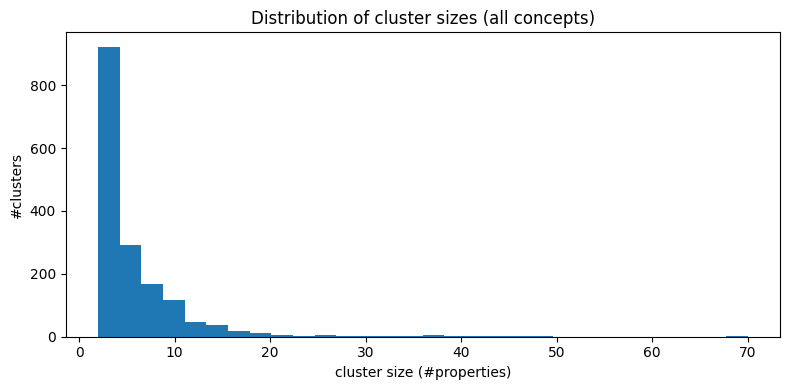

✅ Plots saved:
 - ../data/results/en/en_Sit_Conc_raw_overall_cluster_size_hist.png
 - ../data/results/en/en_Sit_Conc_raw_per_concept_top_codes.pdf


,concept,participant,property,property_norm,code
28,Baseball game,7,Here in Atlanta,atlanta,0
0,Baseball game,1,In Atlanta,atlanta,0
1,Baseball game,1,In Japan,japan,1
2,Baseball game,1,In a park,park,2
3,Baseball game,1,"In some, someones backyard",some someone backyard,3
26,Baseball game,7,"Down at the baseball park here in Atlanta, her...",baseball park atlanta emory,4
84,Baseball game,15,Emory has a baseball team,emory baseball team,4
4,Baseball game,1,"New York Mets, best baseball team",new york mets best baseball team,4
50,Baseball game,10,On Emorys campus you find baseball games from...,emory campus find baseball games time time,4
8,Baseball game,2,When its Saturday afternoon and you go to Tur...,saturday afternoon go turner field watch braves,4


In [26]:
# 9a) overall histogram of cluster sizes (all concepts together)
overall_sizes = best_df_codes["code"].value_counts().sort_values(ascending=False)
plt.figure(figsize=(8,4))
plt.hist(overall_sizes.values, bins=30)
plt.title("Distribution of cluster sizes (all concepts)")
plt.xlabel("cluster size (#properties)")
plt.ylabel("#clusters")
plt.tight_layout()
plt.savefig(f"{OUTPUT_PREFIX}_{DATA_NAME}overall_cluster_size_hist.png", dpi=150)
plt.show()

# 9b) per-concept bar charts of top codes (into a single multipage PDF)
pdf_path = f"{OUTPUT_PREFIX}_{DATA_NAME}_per_concept_top_codes.pdf"
with PdfPages(pdf_path) as pdf:
    for concept, grp in sizes.groupby("concept"):
        top = grp.nlargest(20, "n_properties")  # top 20 codes per concept
        plt.figure(figsize=(8, max(3, 0.35*len(top))))
        plt.barh(top["code"].astype(str), top["n_properties"])
        plt.gca().invert_yaxis()
        plt.title(f"{concept} — top codes by #properties")
        plt.xlabel("#properties")
        plt.ylabel("code")
        plt.tight_layout()
        pdf.savefig()
        plt.close()

print("✅ Plots saved:")
print(" -", f"{OUTPUT_PREFIX}_{DATA_NAME}_overall_cluster_size_hist.png")
print(" -", pdf_path)

# 9c) show a quick preview table inline (like “all rows are coded”)
display(best_df_codes.sort_values(["concept","code","property"]).head(20))